In [13]:
import matplotlib.pyplot as plt
import model.model_builder as model_builder
import numpy as np
import utils.param_loader as param_loader
import utils.unit_conversion as uc

In [14]:
def run_one_param(model, param, range, step_no):
    results = []

    for value in np.linspace(range[0], range[1], step_no):
        model.set_parameter_value(param, value)
        try:
            result = model.run()
            results.append(result)
        except Exception as e:
            print(f"Error running model with {param}={value}: {e}")
            results.append(None)

    return results

In [15]:
params = param_loader.load_parameters()
model = model_builder.ModelBuilder(params)
model.build()
result = model.run()

In [16]:
model.get_symbolic_params()


{'v_pmax': 200.0,
 'v_cmax_mes': 40.0,
 'v_cmax_bs': 40.0,
 'k_c': 48810.630656845766,
 'k_o': 11779094.340329722,
 'k_p': 3307.8278626953334,
 'gamma_star': 0.000381679,
 'g_m': 1.0,
 'g_bs': 0.003,
 'a_o': 0.047,
 'alpha': 0.0,
 'r_mes': 0.4,
 'r_bs': 0.4,
 'r_d': 0.8,
 'solar_irradiance': 237.0,
 'a_air': 0.038,
 'b_air': 289.15,
 'rel_humidity': 25.0,
 'rel_soil_wetness': 0.33,
 'co2_atm': 405.0,
 'o2_atm': 210000.0,
 'v_pmax_ea': 70373.0,
 'v_pmax_hd': 117910.0,
 'v_pmax_delta_s': 376.0,
 'v_cmax_ea': 67294.0,
 'v_cmax_hd': 144568.0,
 'v_cmax_delta_s': 472.0,
 'k_c_ea': 64200.0,
 'k_o_ea': 10500.0,
 'k_p_ea': 38300.0,
 'r_ea': 66400.0,
 'gamma_star_ea': 31100.0,
 'a_o_ea': 1630.0,
 'g_m_ea': 49800.0,
 'psi_sat': -882.5985000000001,
 'b': 4.38,
 'k_sat': 56.28,
 'leaf_water_potential': -1000000.0,
 'k_l': 5e-09,
 'f_canopy': 0.8,
 'alpha_mes': 0.85,
 'rho_mes': 0.05,
 'tau_mes': 0.1,
 'gamma_mes': 0.3,
 'alpha_bs': 0.8,
 'rho_bs': 0.1,
 'tau_bs': 0.1,
 'gamma_bs': 0.2,
 'rho_soil':

In [17]:
result

{'max_water_uptake': 0.0044329228700316515,
 'transpiration_rate': 0.003200065849005395,
 'irradiance_mes': 165.59664000000004,
 'irradiance_bs': 18.125760000000003,
 'convective_cooling': 26.698117129757925,
 'transpirative_cooling': 142.21092632979975,
 'conductive_heat_transfer': -9.327936147928995,
 'radiative_cooling_mes': 6.015532688366024,
 'radiative_cooling_bs': 8.797823852071225,
 'g_s_m_s': 0.0031361356266274673,
 'v_pmax': 217.00723332714105,
 'v_pmax_v_c': 220.3649515024876,
 'v_cmax_mes': 42.2549657190693,
 'v_cmax_mes_v_c': 43.88640295429389,
 'v_cmax_bs': 43.22985374780552,
 'k_c_mes': 53325.25074470993,
 'k_o_mes': 11950753.746918395,
 'k_p': 3487.083454825356,
 'gamma_star_mes': 0.000398390607161046,
 'a_o': 0.0471537513930725,
 'r_mes': 0.4383237469685812,
 'co2_uptake_rate': 11.76761211211075,
 'pepc_rate': 168.58953583286154,
 'co2_assimilation_rate_bs': 8.618593741471955,
 'co2_assimilation_rate_mes': 3.149018370641324,
 'o2_bs': 8471266.477634389,
 'co2_bs': 2157

In [18]:
model.build()
co2_atm = run_one_param(model, 'co2_atm', (uc.ubar_to_molar_concentration(0), uc.ubar_to_molar_concentration(800)), 100)

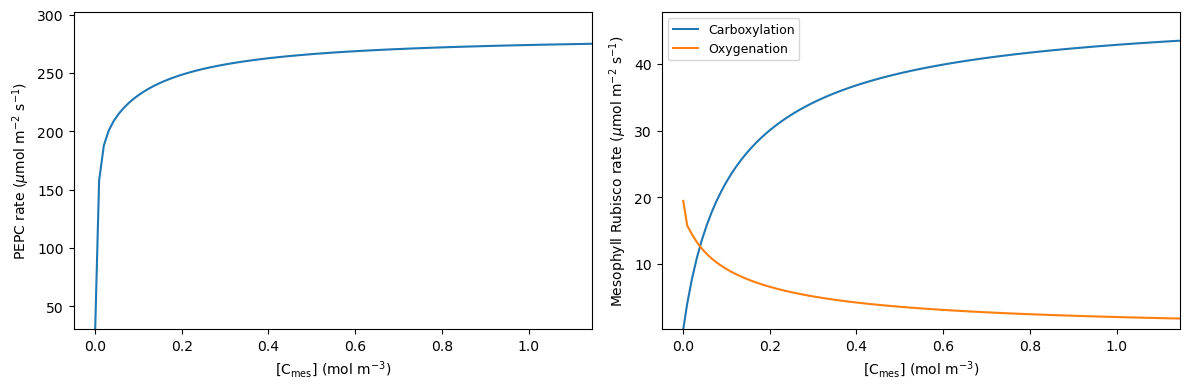

In [19]:
co2_mes = [(value['co2_mes'] * 1e-6) for value in co2_atm]
pepc_rate = [value['pepc_rate'] for value in co2_atm]
rubisco_co2_rate = [value['rubisco_rate_co2_mes'] for value in co2_atm]
rubisco_o2_rate = [value['rubisco_rate_o2_mes'] for value in co2_atm]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Plot PEPC rate
axs[0].plot(co2_mes, pepc_rate)
axs[0].set_xlabel('[C$_\\text{mes}$] (mol m$^{-3}$)')
axs[0].set_ylabel('PEPC rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[0].set_xlim(np.min(co2_mes)-0.05, np.max(co2_mes))
axs[0].set_ylim(np.min(pepc_rate), np.max(pepc_rate) * 1.1)

# Plot Rubisco rate
axs[1].plot(co2_mes, rubisco_co2_rate, label='Carboxylation')
axs[1].plot(co2_mes, rubisco_o2_rate, label='Oxygenation')
axs[1].set_xlabel('[C$_\\text{mes}$] (mol m$^{-3}$)')
axs[1].set_ylabel('Mesophyll Rubisco rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[1].set_xlim(np.min(co2_mes) -0.05, np.max(co2_mes))
axs[1].set_ylim(np.min(rubisco_co2_rate), np.max(rubisco_co2_rate) * 1.1)
axs[1].legend(fontsize=9)

plt.tight_layout()

plt.savefig("plots/validation/michaelis-menten_pepc_rubisco.png", dpi=300, bbox_inches='tight')

In [20]:
model.build()
irradiance = run_one_param(model, 'solar_irradiance', (-250, 763), 100)

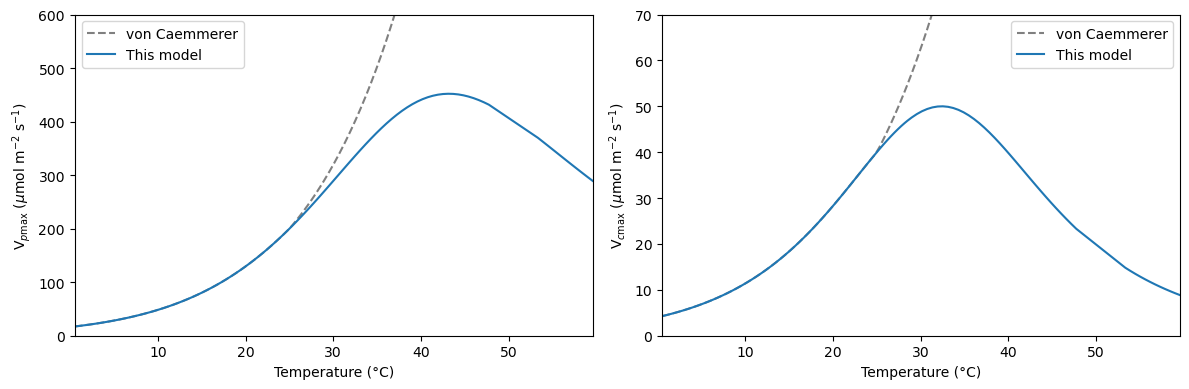

In [21]:
mesophyll_temp = [(value['temp_mes'] - 273.15) for value in irradiance]
v_cmax_mes = [value['v_cmax_mes'] for value in irradiance]
v_cmax_mes_v_c = [value['v_cmax_mes_v_c'] for value in irradiance]
v_pmax = [value['v_pmax'] for value in irradiance]
v_pmax_v_c = [value['v_pmax_v_c'] for value in irradiance]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Plot mesophyll temperature
axs[0].plot(mesophyll_temp, np.maximum(v_pmax, v_pmax_v_c), linestyle='--', color='grey', label='von Caemmerer')
axs[0].plot(mesophyll_temp, v_pmax, label='This model')
axs[0].set_xlabel('Temperature (°C)')
axs[0].set_ylabel('V$_{p\\max}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[0].set_xlim(np.min(mesophyll_temp), np.max(mesophyll_temp))
axs[0].set_ylim(0, 600)
axs[0].legend(loc='upper left')

# Plot Vcmax and Vpmax
axs[1].plot(mesophyll_temp, np.maximum(v_cmax_mes, v_cmax_mes_v_c), linestyle='--', color='grey', label='von Caemmerer')
axs[1].plot(mesophyll_temp, v_cmax_mes, label='This model')
axs[1].set_xlabel('Temperature (°C)')
axs[1].set_ylabel('V$_{c\\max}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[1].set_xlim(np.min(mesophyll_temp), np.max(mesophyll_temp))
axs[1].set_ylim(0, 70)
axs[1].legend()

plt.tight_layout()

plt.savefig("plots/validation/enzyme_temp_dependence.png", dpi=300, bbox_inches='tight')

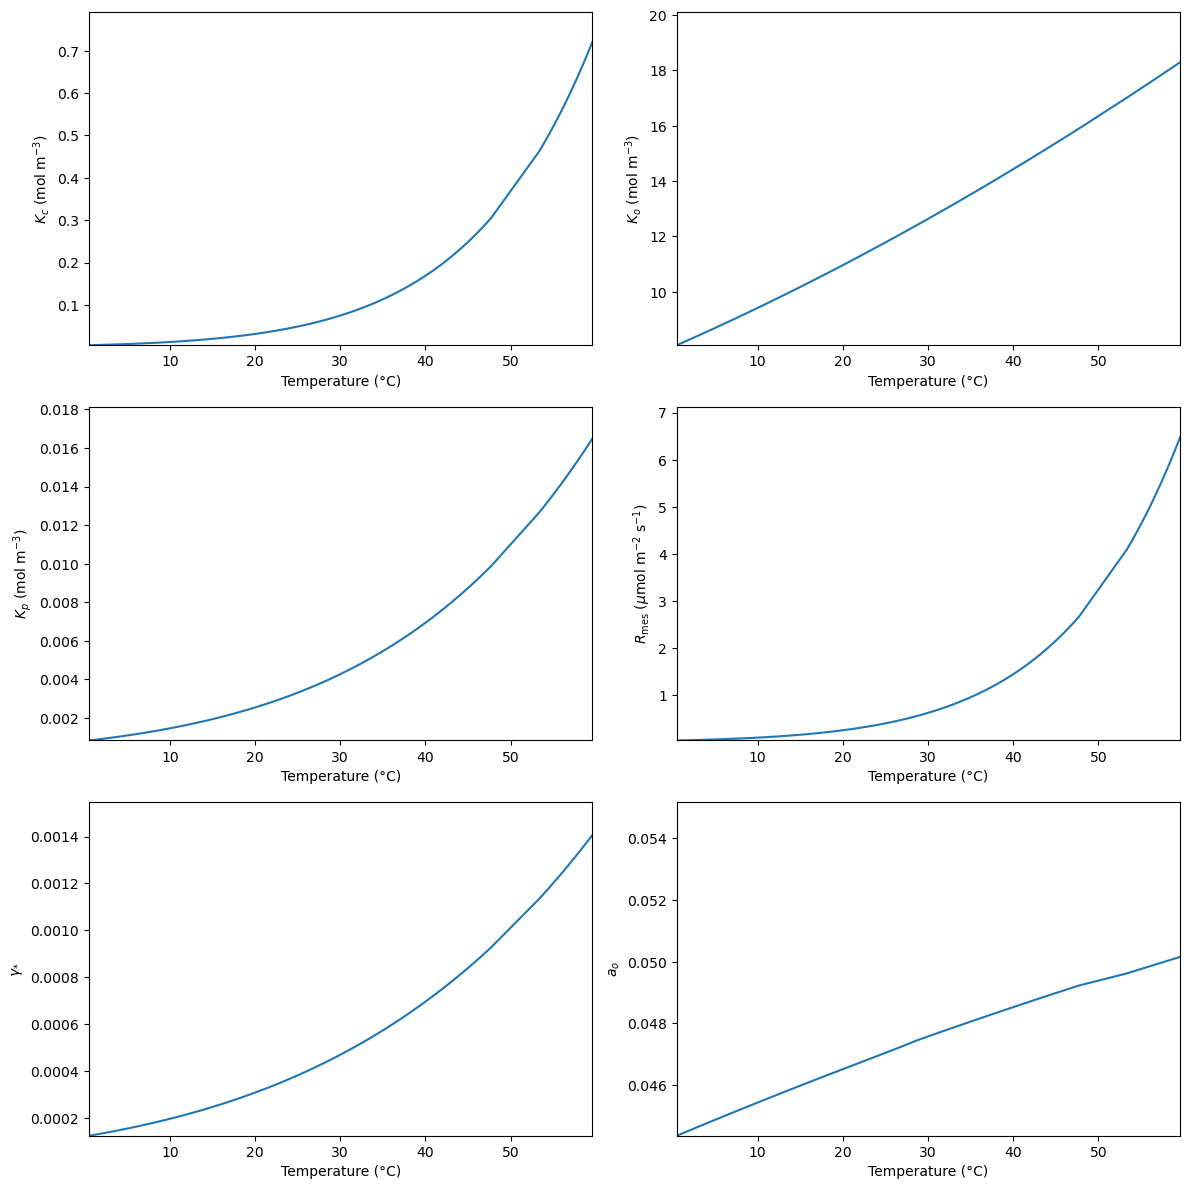

In [22]:
mesophyll_temp = [(value['temp_mes'] - 273.15) for value in irradiance]
k_c_mes = [(value['k_c_mes'] * 1e-6) for value in irradiance]
k_o_mes = [(value['k_o_mes'] * 1e-6) for value in irradiance]
k_p = [(value['k_p'] * 1e-6) for value in irradiance]
gamma_star_mes = [value['gamma_star_mes'] for value in irradiance]
a_o = [value['a_o'] for value in irradiance]
r_mes = [value['r_mes'] for value in irradiance]

fig, axs = plt.subplots(3, 2, figsize=(12, 12))

axs[0, 0].plot(mesophyll_temp, k_c_mes)
axs[0, 0].set_xlabel('Temperature (°C)')
axs[0, 0].set_ylabel('$K_c$ (mol m$^{-3}$)')
axs[0, 0].set_xlim(np.min(mesophyll_temp), np.max(mesophyll_temp))
axs[0, 0].set_ylim(np.min(k_c_mes), np.max(k_c_mes) * 1.1)

axs[0, 1].plot(mesophyll_temp, k_o_mes)
axs[0, 1].set_xlabel('Temperature (°C)')
axs[0, 1].set_ylabel('$K_o$ (mol m$^{-3}$)')
axs[0, 1].set_xlim(np.min(mesophyll_temp), np.max(mesophyll_temp))
axs[0, 1].set_ylim(np.min(k_o_mes), np.max(k_o_mes) * 1.1)

axs[1, 0].plot(mesophyll_temp, k_p)
axs[1, 0].set_xlabel('Temperature (°C)')
axs[1, 0].set_ylabel('$K_p$ (mol m$^{-3}$)')
axs[1, 0].set_xlim(np.min(mesophyll_temp), np.max(mesophyll_temp))
axs[1, 0].set_ylim(np.min(k_p), np.max(k_p) * 1.1)

axs[1, 1].plot(mesophyll_temp, r_mes)
axs[1, 1].set_xlabel('Temperature (°C)')
axs[1, 1].set_ylabel('$R_{\\text{mes}}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[1, 1].set_xlim(np.min(mesophyll_temp), np.max(mesophyll_temp))
axs[1, 1].set_ylim(np.min(r_mes), np.max(r_mes) * 1.1)

axs[2, 0].plot(mesophyll_temp, gamma_star_mes)
axs[2, 0].set_xlabel('Temperature (°C)')
axs[2, 0].set_ylabel('$\\gamma_{*}$')
axs[2, 0].set_xlim(np.min(mesophyll_temp), np.max(mesophyll_temp))
axs[2, 0].set_ylim(np.min(gamma_star_mes), np.max(gamma_star_mes) * 1.1)

axs[2, 1].plot(mesophyll_temp, a_o)
axs[2, 1].set_xlabel('Temperature (°C)')
axs[2, 1].set_ylabel('$a_o$')
axs[2, 1].set_xlim(np.min(mesophyll_temp), np.max(mesophyll_temp))
axs[2, 1].set_ylim(np.min(a_o), np.max(a_o) * 1.1)

plt.tight_layout()

plt.savefig("plots/validation/enzyme_params_temp_dependence.png", dpi=300, bbox_inches='tight')


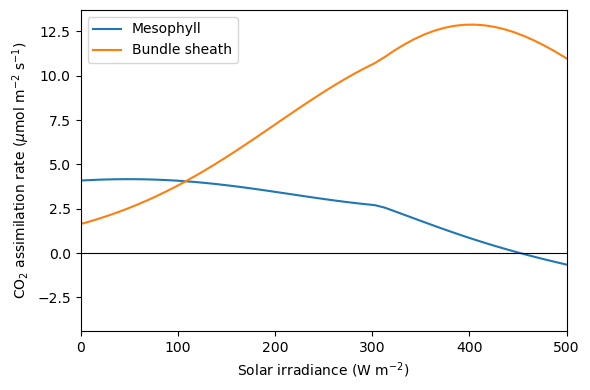

In [23]:
solar_irradiance = np.linspace(-250, 763, 100)
a_mes = [value['co2_assimilation_rate_mes'] for value in irradiance]
a_bs = [value['co2_assimilation_rate_bs'] for value in irradiance]

plt.figure(figsize=(6, 4))
plt.plot(solar_irradiance, a_mes, label='Mesophyll')
plt.plot(solar_irradiance, a_bs, label='Bundle sheath')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('Solar irradiance (W m$^{-2}$)')
plt.ylabel('CO$_2$ assimilation rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')
plt.xlim(0,500)
plt.legend()
plt.tight_layout()

In [24]:
model.build()
irradiance_steps = run_one_param(model, 'solar_irradiance', (0, 500), 100)

In [25]:
solar_irradiance_steps = np.linspace(0, 500, 100)
irradiance_mes = [value['irradiance_mes'] for value in irradiance_steps]
irradiance_bs = [value['irradiance_bs'] for value in irradiance_steps]
mesophyll_temp_steps = [(value['temp_mes'] - 273.15) for value in irradiance_steps]
bundle_sheath_temp_steps = [(value['temp_bs'] - 273.15) for value in irradiance_steps]
air_temperature_steps = [(value['temp_air'] - 273.15) for value in irradiance_steps]
convective_cooling = [value['convective_cooling'] for value in irradiance_steps]
transpirative_cooling = [value['transpirative_cooling'] for value in irradiance_steps]
conductive_cooling = [value['conductive_heat_transfer'] for value in irradiance_steps]
conductive_cooling_bs = [-(value['conductive_heat_transfer']) for value in irradiance_steps]
radiative_cooling_mes = [value['radiative_cooling_mes'] for value in irradiance_steps]
radiative_cooling_bs = [value['radiative_cooling_bs'] for value in irradiance_steps]

#add all cooling terms
all_absorbed = np.array(irradiance_mes) + np.array(irradiance_bs)

print(all_absorbed)
print(f"Solar irradiance: {solar_irradiance_steps} W/m²")

[  0.           3.91515152   7.83030303  11.74545455  15.66060606
  19.57575758  23.49090909  27.40606061  31.32121212  35.23636364
  39.15151515  43.06666667  46.98181818  50.8969697   54.81212121
  58.72727273  62.64242424  66.55757576  70.47272727  74.38787879
  78.3030303   82.21818182  86.13333333  90.04848485  93.96363636
  97.87878788 101.79393939 105.70909091 109.62424242 113.53939394
 117.45454545 121.36969697 125.28484848 129.2        133.11515152
 137.03030303 140.94545455 144.86060606 148.77575758 152.69090909
 156.60606061 160.52121212 164.43636364 168.35151515 172.26666667
 176.18181818 180.0969697  184.01212121 187.92727273 191.84242424
 195.75757576 199.67272727 203.58787879 207.5030303  211.41818182
 215.33333333 219.24848485 223.16363636 227.07878788 230.99393939
 234.90909091 238.82424242 242.73939394 246.65454545 250.56969697
 254.48484848 258.4        262.31515152 266.23030303 270.14545455
 274.06060606 277.97575758 281.89090909 285.80606061 289.72121212
 293.63636

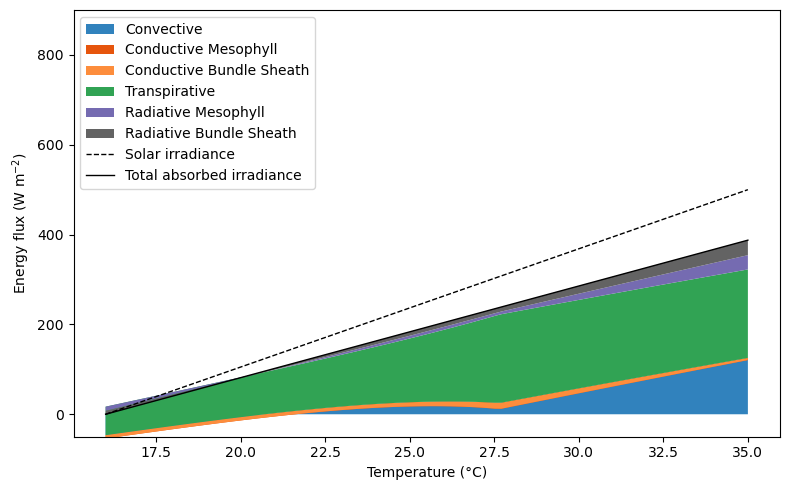

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))

cmap = plt.get_cmap("tab20c")

ax.stackplot(
    air_temperature_steps,
    convective_cooling,
    conductive_cooling,
    conductive_cooling_bs,
    transpirative_cooling,
    radiative_cooling_mes,
    radiative_cooling_bs,
    labels=["Convective",  "Conductive Mesophyll", "Conductive Bundle Sheath", "Transpirative", "Radiative Mesophyll", "Radiative Bundle Sheath"],
    colors=[cmap.colors[0], cmap.colors[4], cmap.colors[5], cmap.colors[8], cmap.colors[12], cmap.colors[16]]
)

ax.plot(air_temperature_steps, solar_irradiance_steps, 'k--', linewidth=1, label="Solar irradiance")
ax.plot(air_temperature_steps, all_absorbed, 'k-', linewidth=1, label="Total absorbed irradiance")

ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Energy flux (W m$^{-2}$)")
ax.set_ylim(-50, 900)
ax.legend(loc='upper left')
plt.tight_layout()

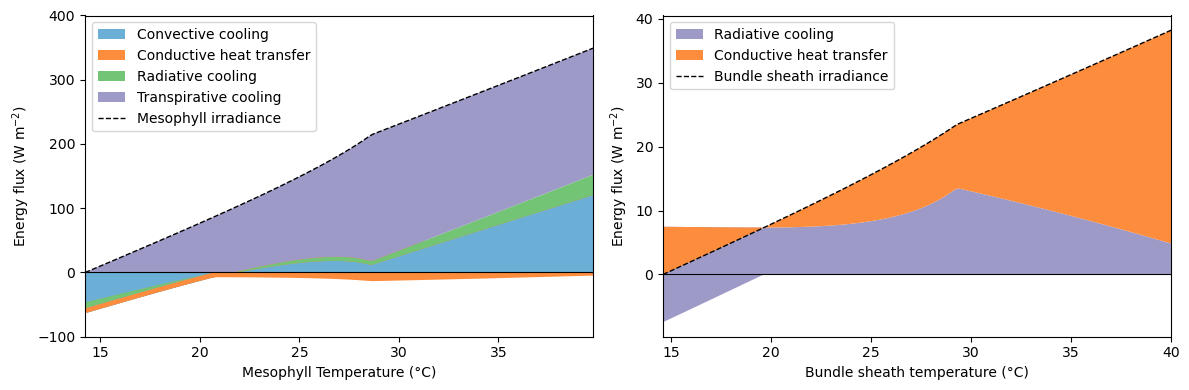

In [27]:
def split_pos_neg(arr):
    arr = np.array(arr)
    pos = np.where(arr > 0, arr, 0)
    neg = np.where(arr < 0, arr, 0)
    return pos, neg

conv_mes_pos, conv_mes_neg = split_pos_neg(convective_cooling)
cond_mes_pos, cond_mes_neg = split_pos_neg(conductive_cooling)
rad_mes_pos, rad_mes_neg = split_pos_neg(radiative_cooling_mes)
cond_bs_pos, cond_bs_neg = split_pos_neg(conductive_cooling_bs)
rad_bs_pos, rad_bs_neg = split_pos_neg(radiative_cooling_bs)

cmap = plt.get_cmap("tab20c")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Mesophyll panel
ax1.axhline(0, color='black', linewidth=0.8)

ax1.stackplot(
    mesophyll_temp_steps,
    convective_cooling,
    conductive_cooling,
    radiative_cooling_mes,
    transpirative_cooling,
    labels=["Convective cooling", "Conductive heat transfer",
            "Radiative cooling", "Transpirative cooling"],
    colors=[cmap.colors[1], cmap.colors[5], cmap.colors[9], cmap.colors[13]]
)

ax1.stackplot(
    mesophyll_temp_steps,
    conv_mes_neg,
    rad_mes_neg,
    cond_mes_neg,
    colors=[cmap.colors[1], cmap.colors[9], cmap.colors[5]]
)

ax1.plot(mesophyll_temp_steps, irradiance_mes, 'k--', linewidth=1, label="Mesophyll irradiance")
ax1.set_xlabel("Mesophyll Temperature (°C)")
ax1.set_ylabel("Energy flux (W m$^{-2}$)")
ax1.set_xlim(np.min(mesophyll_temp_steps), np.max(mesophyll_temp_steps))
ax1.set_ylim(-100, 400)
ax1.legend(loc='upper left')

# Bundle sheath panel
ax2.axhline(0, color='black', linewidth=0.8)

ax2.stackplot(
    bundle_sheath_temp_steps,
    conductive_cooling_bs,
    radiative_cooling_bs,
    
    labels=["Radiative cooling","Conductive heat transfer"],
    colors=[cmap.colors[13], cmap.colors[5]]
)

ax2.stackplot(
    bundle_sheath_temp_steps,
    rad_bs_neg,
    colors=[cmap.colors[13]]
)

ax2.plot(bundle_sheath_temp_steps, irradiance_bs, 'k--', linewidth=1, label="Bundle sheath irradiance")
ax2.set_xlabel("Bundle sheath temperature (°C)")
ax2.set_ylabel("Energy flux (W m$^{-2}$)")
ax2.set_xlim(np.min(bundle_sheath_temp_steps), np.max(bundle_sheath_temp_steps))
ax2.legend(loc='upper left')

plt.tight_layout()

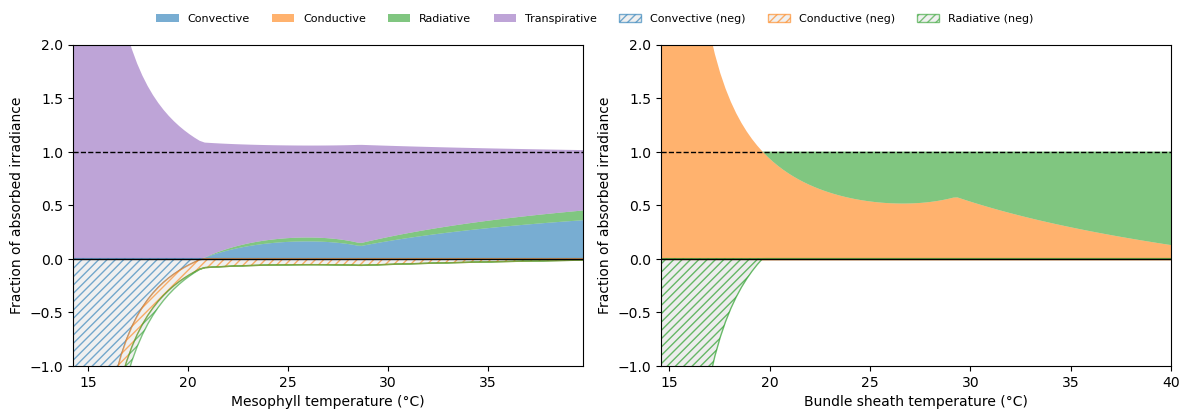

In [28]:
# add small epsilon to avoid division by zero
epsilon = 1e-3


# Convert to numpy arrays for vector operations
irr = np.array(irradiance_mes) + epsilon

conv = np.array(convective_cooling) / irr
cond = np.array(conductive_cooling) / irr
rad  = np.array(radiative_cooling_mes) / irr
trans = np.array(transpirative_cooling) / irr

# Separate positives and negatives
pos_parts = [np.clip(conv, 0, None),
             np.clip(cond, 0, None),
             np.clip(rad,  0, None),
             np.clip(trans,0, None)]
neg_parts = [np.clip(conv, None, 0),
             np.clip(cond, None, 0),
             np.clip(rad,  None, 0)]

cmap = plt.get_cmap("tab20c")

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']
colors_neg =[cmap.colors[1], cmap.colors[5], cmap.colors[9], cmap.colors[13]]
labels = ["Convective", "Conductive", "Radiative", "Transpirative"]

# Convert to numpy arrays for vector operations
irr_bs = np.array(irradiance_bs) + epsilon


cond_bs = np.array(conductive_cooling_bs) / irr_bs
rad_bs  = np.array(radiative_cooling_bs) / irr_bs

# Separate positives and negatives
pos_parts_bs = [np.clip(cond_bs, 0, None),
             np.clip(rad_bs,  0, None)]
neg_parts_bs = [np.clip(cond_bs, None, 0),
             np.clip(rad_bs,  None, 0)]

colors_bs = ['#ff7f0e', '#2ca02c']
labels_bs = ["Conductive", "Radiative"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Positive stack (solid)
ax[0].stackplot(mesophyll_temp_steps, *pos_parts,
             colors=colors, labels=labels, alpha=0.6)

# Negative stack (hatched) – need manual plotting to add hatch
from itertools import accumulate
baseline = np.zeros_like(mesophyll_temp_steps)
for part, color, label in zip(neg_parts, colors, labels):
    next_level = baseline + part
    poly = ax[0].fill_between(mesophyll_temp_steps, baseline, next_level,
                           facecolor='#e6e6e6', edgecolor=color, hatch='////',
                           alpha=0.6, label=f"{label} (neg)")
    baseline = next_level

# Reference line at 1 (100% of irradiance)
ax[0].axhline(1, color='black', linestyle='--', linewidth=1)
ax[0].axhline(0, color='black', linewidth=1)

ax[0].set_xlabel("Mesophyll temperature (°C)")
ax[0].set_ylabel("Fraction of absorbed irradiance")
ax[0].set_xlim(np.min(mesophyll_temp_steps), np.max(mesophyll_temp_steps))
ax[0].set_ylim(-1, 2)

#ax[0].legend(loc='upper right', fontsize=8)
handles, labels = ax[0].get_legend_handles_labels()

# Positive stack (solid)
ax[1].stackplot(bundle_sheath_temp_steps, *pos_parts_bs,
             colors=colors_bs, labels=labels_bs, alpha=0.6)

# Negative stack (hatched) – need manual plotting to add hatch
from itertools import accumulate
baseline = np.zeros_like(bundle_sheath_temp_steps)
for part, color, label in zip(neg_parts_bs, colors_bs, labels_bs):
    next_level = baseline + part
    poly = ax[1].fill_between(bundle_sheath_temp_steps, baseline, next_level,
                           facecolor='#e6e6e6', edgecolor=color, hatch='////',
                           alpha=0.7, label=f"{label} (neg)")
    baseline = next_level

# Reference line at 1 (100% of irradiance)
ax[1].axhline(1, color='black', linestyle='--', linewidth=1)
ax[1].axhline(0, color='black', linewidth=1)

ax[1].set_xlabel("Bundle sheath temperature (°C)")
ax[1].set_ylabel("Fraction of absorbed irradiance")
ax[1].set_xlim(np.min(bundle_sheath_temp_steps), np.max(bundle_sheath_temp_steps))
ax[1].set_ylim(-1, 2)

#ax[1].legend(fontsize=8)

fig.legend(
    handles,
    labels,
    loc='upper center',       # center horizontally
    ncol=8,                   # number of columns in the legend
    bbox_to_anchor=(0.5, 1.05),  # fine-tune position above subplots
    fontsize=8,
    frameon=False
)

plt.tight_layout()

plt.savefig("plots/validation/cooling_partitioning.png", dpi=300, bbox_inches='tight')

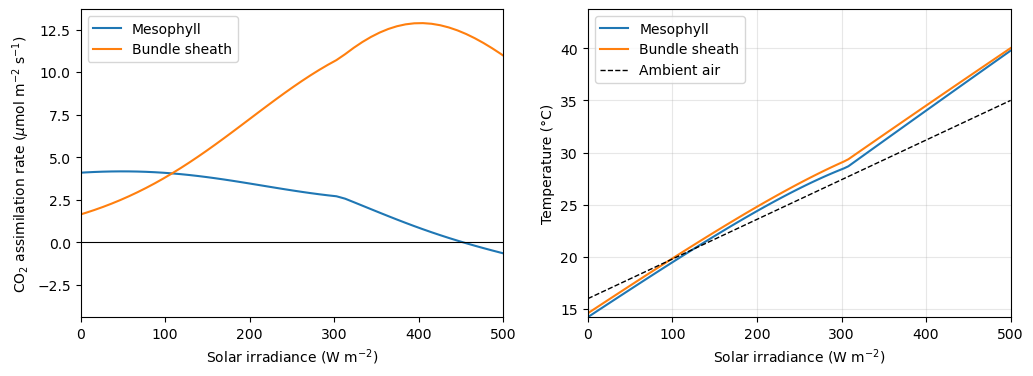

In [ ]:
#plot all three temperatures against solar_irradiance_steps


fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(solar_irradiance, a_mes, label='Mesophyll')
axs[0].plot(solar_irradiance, a_bs, label='Bundle sheath')
axs[0].axhline(0, color='black', linewidth=0.)
axs[0].set_xlabel('Solar irradiance (W m$^{-2}$)')
axs[0].set_ylabel('CO$_2$ assimilation rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[0].set_xlim(0,500)
axs[0].legend()


axs[1].plot(solar_irradiance_steps, mesophyll_temp_steps, label='Mesophyll')
axs[1].plot(solar_irradiance_steps, bundle_sheath_temp_steps, label='Bundle sheath')
axs[1].plot(solar_irradiance_steps, air_temperature_steps, 'k--', linewidth=1, label='Ambient air')
axs[1].set_xlabel('Solar irradiance (W m$^{-2}$)')
axs[1].set_ylabel('Temperature (°C)')
axs[1].set_xlim(0, 500)
axs[1].set_ylim(np.min(mesophyll_temp_steps), np.max(mesophyll_temp_steps) * 1.1)
axs[1].grid(alpha=0.3)
axs[1].legend()

plt.savefig("plots/validation/assimilation_rate.png", dpi=300, bbox_inches='tight')


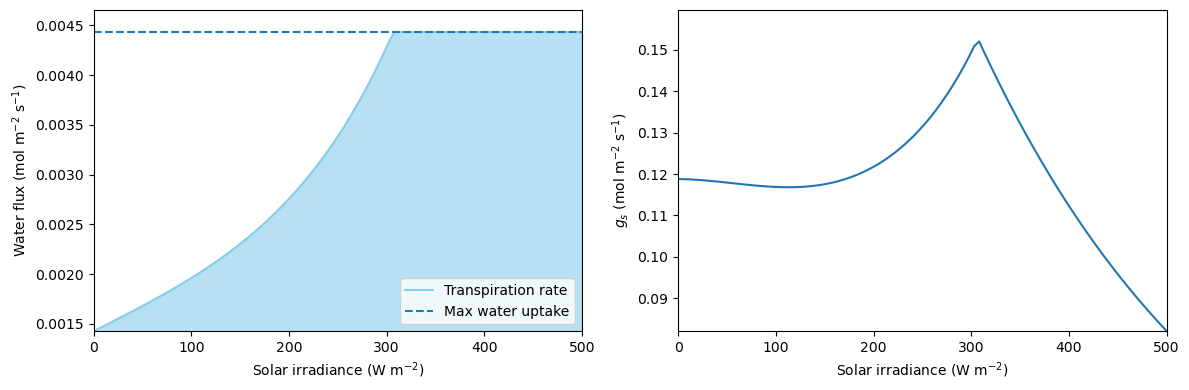

In [35]:
max_water_uptake = [value['max_water_uptake'] for value in irradiance_steps]
transpiration_rate = [value['transpiration_rate'] for value in irradiance_steps]
g_s = [value['g_s'] for value in irradiance_steps]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(solar_irradiance_steps, transpiration_rate, label='Transpiration rate', color='skyblue')
axs[0].plot(solar_irradiance_steps, max_water_uptake, label='Max water uptake', linestyle='--')
axs[0].fill_between(solar_irradiance_steps, transpiration_rate, color='skyblue', alpha=0.6)
axs[0].set_xlabel('Solar irradiance (W m$^{-2}$)')
axs[0].set_ylabel('Water flux (mol m$^{-2}$ s$^{-1}$)')
axs[0].set_xlim(np.min(solar_irradiance_steps), np.max(solar_irradiance_steps))
axs[0].set_ylim(np.min(transpiration_rate), np.max(max_water_uptake) * 1.05)
axs[0].legend(loc='lower right')

axs[1].plot(solar_irradiance_steps, g_s, label='Stomatal conductance')
axs[1].set_xlabel('Solar irradiance (W m$^{-2}$)')
axs[1].set_ylabel('$g_s$ (mol m$^{-2}$ s$^{-1}$)')
axs[1].set_xlim(np.min(solar_irradiance_steps), np.max(solar_irradiance_steps))
axs[1].set_ylim(np.min(g_s), np.max(g_s) * 1.05)

plt.tight_layout()

plt.savefig("plots/validation/transpiration.png", dpi=300, bbox_inches='tight')
